# Filtros de Média, Mediana, Moda e Máxima (sem OpenCV)

**Ideia geral:** para cada pixel da imagem, olhamos uma janelinha 5x5 em volta dele e trocamos o pixel por um valor calculado a partir dessa janela:

| Filtro  | Novo valor do pixel |
|---------|---------------------|
| Média   | média dos valores da janela (feito com convolução) |
| Mediana | valor do meio, depois de ordenar a janela |
| Moda    | valor que mais se repete na janela |
| Máxima  | maior valor da janela |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

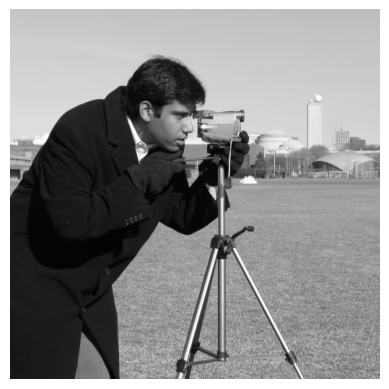

In [2]:
img = data.camera()   # imagem de exemplo já em escala de cinza
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

In [3]:
def implot(img, img_filt, nomefiltro, kernelsize):
  plt.figure(figsize=(10, 5))

  plt.subplot(1,2,1)
  plt.imshow(img, cmap="gray")
  plt.title("Imagem Original")
  plt.axis("off")

  plt.subplot(1,2,2)
  plt.imshow(img_filt, cmap="gray")
  plt.title("Filtro " + nomefiltro + " " + kernelsize)
  plt.axis("off")

  plt.show()

## Convolução manual

1. Aumentamos a imagem com uma borda (`np.pad`) para a janela caber também nos pixels da beirada.
2. Percorremos cada pixel `(i, j)` da imagem.
3. Pegamos a janela do tamanho do kernel em volta do pixel.
4. Multiplicamos a janela pelo kernel, elemento por elemento, e somamos tudo. Esse é o novo valor do pixel.

In [4]:
def convolucao(img, kernel):
  k = kernel.shape[0]          # tamanho do kernel (ex: 5)
  borda = k // 2               # quantos pixels de borda (ex: 2)

  img_borda = np.pad(img, borda, mode='edge')   # passo 1
  saida = np.zeros(img.shape)

  for i in range(img.shape[0]):                 # passo 2
    for j in range(img.shape[1]):
      janela = img_borda[i:i+k, j:j+k]          # passo 3
      saida[i, j] = np.sum(janela * kernel)     # passo 4

  return saida.astype(np.uint8)

## 1 - Filtro de Média
Kernel 5x5 com todos os valores iguais a 1/25. Multiplicar por 1/25 e somar é o mesmo que tirar a média dos 25 pixels.

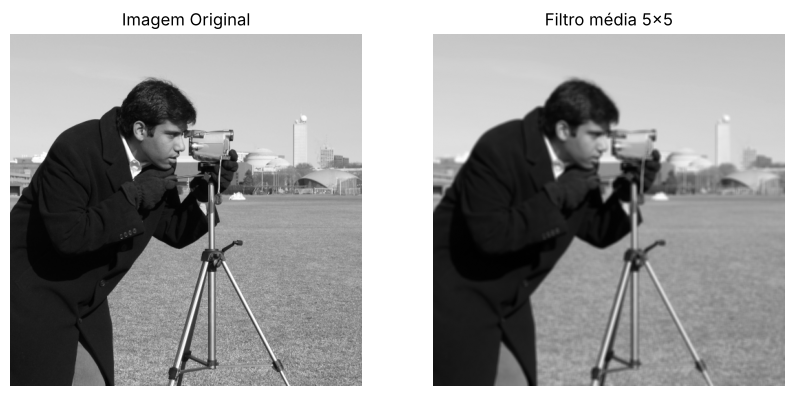

In [5]:
def filtro_media(img, k):
  kernel = np.ones((k, k)) / (k * k)
  return convolucao(img, kernel)

img_filt = filtro_media(img, 5)
implot(img, img_filt, 'média', '5x5')

## 2 - Filtro de Mediana
Mesma janela deslizante, mas em vez de multiplicar pelo kernel, pegamos a mediana da janela.

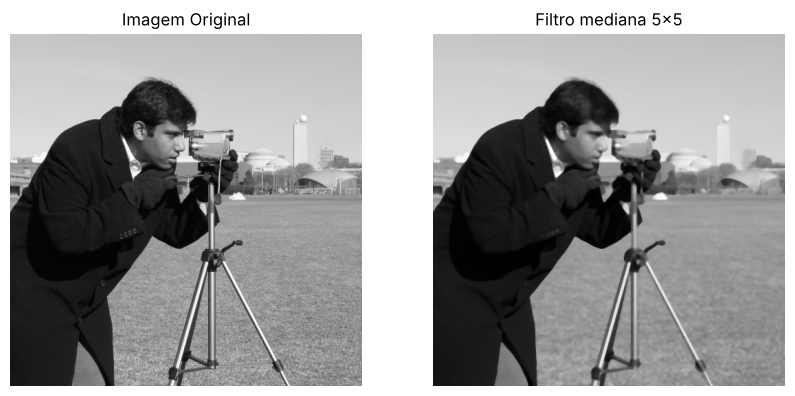

In [6]:
def filtro_mediana(img, k):
  borda = k // 2
  img_borda = np.pad(img, borda, mode='edge')
  saida = np.zeros(img.shape)

  for i in range(img.shape[0]):
    for j in range(img.shape[1]):
      janela = img_borda[i:i+k, j:j+k]
      saida[i, j] = np.median(janela)

  return saida.astype(np.uint8)

img_filt = filtro_mediana(img, 5)
implot(img, img_filt, 'mediana', '5x5')

## 3 - Filtro de Moda
`np.unique` devolve os valores diferentes da janela e quantas vezes cada um aparece. Ficamos com o que aparece mais vezes.

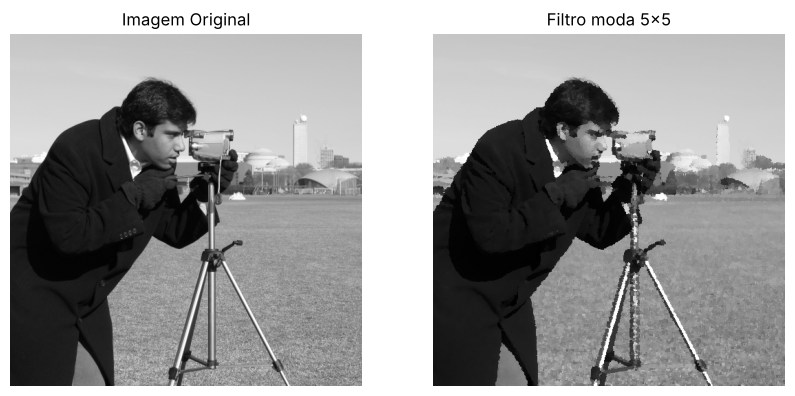

In [7]:
def filtro_moda(img, k):
  borda = k // 2
  img_borda = np.pad(img, borda, mode='edge')
  saida = np.zeros(img.shape)

  for i in range(img.shape[0]):
    for j in range(img.shape[1]):
      janela = img_borda[i:i+k, j:j+k]
      valores, contagens = np.unique(janela, return_counts=True)
      saida[i, j] = valores[np.argmax(contagens)]

  return saida.astype(np.uint8)

img_filt = filtro_moda(img, 5)
implot(img, img_filt, 'moda', '5x5')

## 4 - Filtro de Máxima
Pegamos o maior valor da janela. A imagem fica mais clara e as áreas claras "crescem".

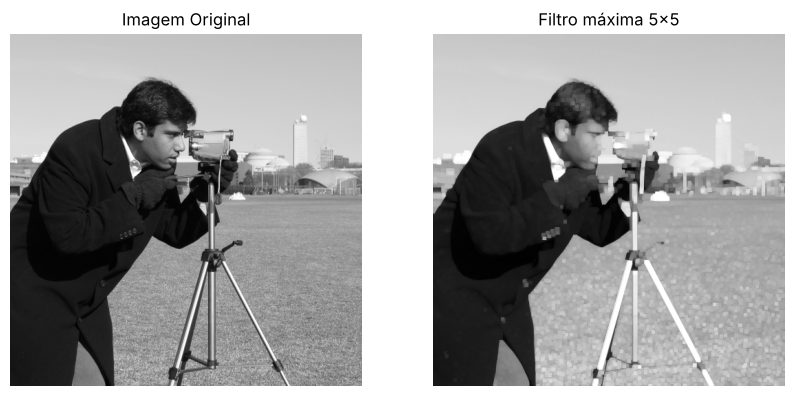

In [8]:
def filtro_maxima(img, k):
  borda = k // 2
  img_borda = np.pad(img, borda, mode='edge')
  saida = np.zeros(img.shape)

  for i in range(img.shape[0]):
    for j in range(img.shape[1]):
      janela = img_borda[i:i+k, j:j+k]
      saida[i, j] = np.max(janela)

  return saida.astype(np.uint8)

img_filt = filtro_maxima(img, 5)
implot(img, img_filt, 'máxima', '5x5')